# 01 · Quickstart

From public photometry to a Δχ² map and figures in a few minutes, for the planetary event **MOA-2022-BLG-091**
(= KMT-2022-BLG-0114; Han et al. 2025). The steps:

1. download the public KMTNet photometry,
2. fit a binary-lens solution,
3. normalise the error bars,
4. compute a small Δχ² map over (log *s*, log *q*),
5. plot the light curve and the lens geometry.

Every later notebook explains one of these steps in detail.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures

## 1. Data

`lenscape.datasets.kmtnet` downloads the KMTNet pySIS photometry of an event from the
[KMTNet archive](https://kmtnet.kasi.re.kr/~ulens/) (once; it is cached in `~/.cache/lenscape/data`).
The time axis is HJD − 2450000. We keep the 2022 season around the event.

In [2]:
data = lenscape.datasets.kmtnet("KMT-2022-BLG-0114", window=(9600, 9720))
data

Data(736 points, t 9630.85 .. 9719.90, sets {'KMTA22': 140, 'KMTC22': 417, 'KMTS22': 179})

## 2. A solution

A fit needs a starting point near a solution. Here we take one of the four published solutions (Sol B); for a
new event, a coarse map (notebook 06) finds the starting points. `fit_full` optimises all seven parameters
(t0, u0, tE, log s, log q, α, log ρ); the source and blend fluxes of each data set are solved in every step.

In [3]:
p0 = np.array([9657.785, -0.02614, 34.51, np.log10(1.0033), np.log10(4.36e-3), 4.354, -3.0])
chi2, best = lenscape.fit_full(data, p0)
print(f"chi2 = {chi2:.1f} for {len(data)} points")
print("s = %.4f, q = %.2e, alpha = %.3f, tE = %.2f" % (10 ** best[3], 10 ** best[4], best[5], best[2]))

chi2 = 2759.6 for 736 points
s = 1.0015, q = 4.40e-03, alpha = 4.267, tE = 34.64


## 3. Error bars

Photometric error bars are usually underestimated. The standard practice is to scale them per data set so that
χ²/N = 1 at the best fit, and to refit.

In [4]:
k = lenscape.error_factors(data, best)
print({name: round(v, 2) for name, v in k.items()})
data = data.scale_errors(k)
chi2, best = lenscape.fit_full(data, best)
print(f"chi2 = {chi2:.1f} for {len(data)} points")

{'KMTA22': 2.99, 'KMTC22': 1.44, 'KMTS22': 1.9}


chi2 = 733.3 for 736 points


## 4. A small Δχ² map

`lenscape.lattice` fits every point of a (log s, log q) lattice, in stages (see notebook 06). A coarse 7 × 7
lattice around the solution takes a few minutes on a laptop.

> **Resolution vs. runtime.** The runtime grows with the number of lattice points: `gridres = 7` (49 points) takes
> a few minutes; `gridres = 20` (400 points) gives a much finer map but takes about 8 times longer. The published
> map of this event has 50 × 49 points (about 1.5 h on 12 threads).

In [5]:
gridres = 7
logs = np.linspace(-0.006, 0.010, gridres)
logq = np.linspace(-2.55, -2.20, gridres)
result = lenscape.lattice(data, logs, logq, best=best)

lattice 7 x 7 = 49 points; N = 736 (513 evaluated after binning the wings)



Stage 1/5: Coarse seed grid - quick fits on 2 x 2 merged cells, used as starting points


  seed grid: neighbour refinement, pass 1: 13 cells checked, 1 refitted, 1 improved by > 1.0 (max 56.1)


  seed grid: neighbour refinement, pass 2: 13 cells checked, 2 refitted, 2 improved by > 1.0 (max 87.7)


  seed grid: neighbour refinement, pass 3: 14 cells checked, 2 refitted, 2 improved by > 1.0 (max 53.3)


...

recalculate outliers, pass 6: 6 outliers, 1 improved


recalculate outliers, pass 7: 6 outliers, 1 improved


recalculate outliers, pass 8: 6 outliers, 1 improved


recalculate outliers, pass 9: 6 outliers, 1 improved


recalculate outliers, pass 10: 6 outliers, 1 improved
done in 275s; lowest chi2 721.85


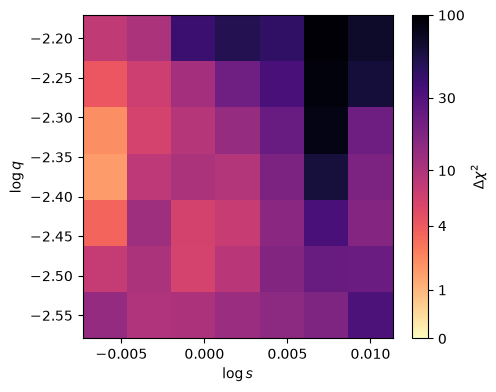

In [6]:
figures.plot_map(result);

## 5. Figures

The light curve with the model and residuals, and the lens configuration (caustic, source trajectory, lines of
equal magnification). pySIS fluxes are difference fluxes, so the magnitudes shown are those of the magnified source.

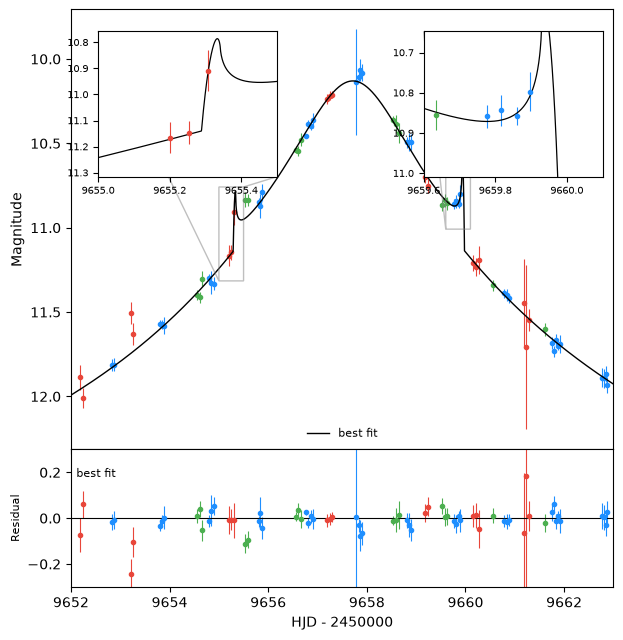

In [7]:
backend = lenscape.make_backend(config.REFINE_BACKEND)
figures.plot_lightcurve(backend, [best], data, labels=["best fit"], window=(9652, 9663),
                        insets=[(9655.0, 9655.5), (9659.6, 9660.1)]);

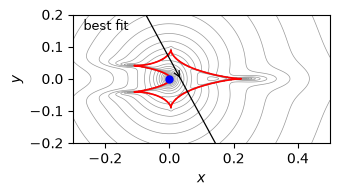

In [8]:
figures.plot_geometry([best], labels=["best fit"], ncols=1, mirror=True);